<a href="https://colab.research.google.com/github/Antx0x/PMP-2026/blob/main/Lab6_exercitiu.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Exercițiu laborator 6: Inferență Bayesiană

O companie de telecomunicații dorește să estimeze rata medie de apeluri primite de un call center într-o oră. Din datele istorice, compania știe că rata medie de apeluri pe oră variază în funcție de perioadele zilei și de anumite zile din săptămână. Într-o anumită perioadă, managerul observă că, timp de 10 ore, au fost primite un total de 180 de apeluri. Să notăm cu $\lambda$ rata medie de apeluri pe oră. Având în vedere că numărul de apeluri pe oră poate fi modelat ca o variabilă Poisson, avem următoarele informații:

- **Datele observate:** În 10 ore, au fost primite 180 de apeluri, ceea ce oferă o rată medie observată de 18 apeluri pe oră.
- **Distribuția verosimilității:** Presupunem că numărul de apeluri pe oră urmează o distribuție Poisson cu parametrul $\lambda$.

Alegând o distribuție Gamma ca distribuție *a priori* pentru $\lambda$ (deoarece este conjugata a priori a distribuției Poisson), determinați distribuția *a posteriori*, un interval HDI de 94% și cea mai probabilă valoare a lui $\lambda$.

*Indicații:*

- Distribuția Poisson cu parametrul $\lambda > 0$ este dată de $P(X = k) = e^{-\lambda}\dfrac{\lambda^k}{k!}$.
- Distribuția Gamma cu parametrii $\alpha, \beta > 0$ este dată de $p(\lambda) = \dfrac{\beta^\alpha}{\Gamma(\alpha)}\lambda^{\alpha-1}e^{-\beta\lambda}$ (cu media $\alpha/\beta$, dispersia $\alpha/\beta^2$ și modul $[(\alpha-1)\vee 0]/\beta$). Cum alegem parametrii $\alpha$ și $\beta$?
- Un interval HDI al unei distribuții (și modul ei) se poate apela în librăria ArviZ cu `plot_posterior`.



Ideea de bază: **posterior ∝ verosimilitate × prior**. Pornim de la ce credem despre $\lambda$ (priorul) și actualizăm cu datele.


Enunțul nu dă $\alpha$ și $\beta$, deci îi alegem noi. Presupunem o medie de aproximativ 20 de apeluri pe oră și o dispersie mare (200), pentru că nu suntem foarte siguri:

$$\frac{\alpha}{\beta} = 20, \quad \frac{\alpha}{\beta^2} = 200 \quad\Rightarrow\quad \beta = 0.1, \quad \alpha = 2$$

Priorul este **Gamma(2, 0.1)**.


Pentru $n$ ore cu $k_1, \dots, k_n$ apeluri, verosimilitatea este:

$$L(\lambda) \propto e^{-n\lambda}\lambda^{\sum k_i}$$

Înmulțim cu priorul și adunăm exponenții:

$$p(\lambda \mid date) \propto \lambda^{\alpha-1}e^{-\beta\lambda} \cdot \lambda^{\sum k_i}e^{-n\lambda} = \lambda^{\alpha+\sum k_i-1}e^{-(\beta+n)\lambda}$$

Rezultatul are forma unei distribuții Gamma, deci:

$$\lambda \mid date \sim \text{Gamma}\left(\alpha + \sum k_i,\ \beta + n\right) = \text{Gamma}(182,\ 10.1)$$


In [ ]:
!pip install -q arviz

import arviz as az
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

In [ ]:
total_apeluri = 180
n_ore = 10

alpha_prior = 2
beta_prior = 0.1

alpha_post = alpha_prior + total_apeluri
beta_post = beta_prior + n_ore

media = alpha_post / beta_post
modul = (alpha_post - 1) / beta_post

print(f"Posterior: Gamma({alpha_post}, {beta_post})")
print(f"Media: {media:.2f}")
print(f"Modul: {modul:.2f}")

Posterior: Gamma(182, 10.1)
Media: 18.02
Modul: 17.92


In [ ]:
rng = np.random.default_rng(42)
esantion = stats.gamma.rvs(
    a=alpha_post, scale=1 / beta_post, size=200_000, random_state=rng
)


try:
    hdi = az.hdi(esantion, hdi_prob=0.94)
except TypeError:
    hdi = az.hdi(esantion, prob=0.94)

print(f"HDI 94%: [{hdi[0]:.2f}, {hdi[1]:.2f}]")

HDI 94%: [15.55, 20.58]


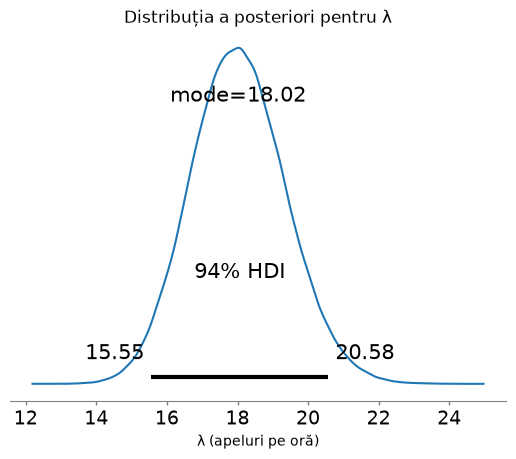

In [ ]:
if hasattr(az, "plot_posterior"):
    az.plot_posterior(esantion, hdi_prob=0.94, point_estimate="mode", round_to=4)
else:
    date = az.from_dict({"posterior": {"lambda": esantion[np.newaxis, :]}})
    az.plot_dist(date, ci_kind="hdi", ci_prob=0.94, point_estimate="mode")

plt.title("Distribuția a posteriori pentru λ")
plt.xlabel("λ (apeluri pe oră)")
plt.show()


- **Distribuția a posteriori:** $\lambda \mid date \sim \text{Gamma}(182,\ 10.1)$
- **Cea mai probabilă valoare (modul):** $\lambda = 181 / 10.1 \approx 17.92$ apeluri pe oră
- **HDI 94%:** aproximativ $[15.5,\ 20.6]$ apeluri pe oră

Rezultatul depinde puțin de prior, dar cele 10 ore de date cântăresc mult mai mult. De aceea, posteriorul este centrat aproape de media observată, 18. HDI și modul de pe grafic vin din eșantionare, deci pot diferi puțin de valorile exacte. Pentru mod, folosește valoarea din formulă, 17.92.